<a href="https://colab.research.google.com/github/camsmugereski/BU-OMDS-Capstone/blob/main/OMDS_ModC1_Week6_Smugereski_Cameron.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Week 6 Jupyter Notebook – Decision Trees and Random Forests
## Predicting Loan Default with Tree-Based Models

### Project Overview

For Week 6, I am continuing to use the Credit Risk dataset from my capstone project. I am keeping `loan_status` as the target variable so I can compare these results with the logistic regression and SVM models from Weeks 4 and 5.

This week, I am using decision trees and random forests to predict whether a borrower defaults. I will start with a basic decision tree and then look at how controlling the depth of the tree affects performance and overfitting. I will also compare the decision tree with a random forest.

The main question I am looking at is:

**How well can decision trees and random forests predict loan default, and does using an ensemble of trees improve performance compared with a single decision tree?**

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from google.colab import files

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.tree import (
    DecisionTreeClassifier,
    plot_tree
)

from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    RocCurveDisplay,
    classification_report
)

pd.set_option('display.max_columns', None)

In [ ]:
uploaded = files.upload()

file_name = list(uploaded.keys())[0]

df = pd.read_csv(file_name)

print("File loaded:", file_name)
print("Dataset shape:", df.shape)

df.head()

Saving credit_risk_dataset 2.csv to credit_risk_dataset 2.csv
File loaded: credit_risk_dataset 2.csv
Dataset shape: (32581, 12)


,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
0,22,59000,RENT,123.0,PERSONAL,D,35000,16.02,1,0.59,Y,3
1,21,9600,OWN,5.0,EDUCATION,B,1000,11.14,0,0.10,N,2
2,25,9600,MORTGAGE,1.0,MEDICAL,C,5500,12.87,1,0.57,N,3
3,23,65500,RENT,4.0,MEDICAL,C,35000,15.23,1,0.53,N,2
4,24,54400,RENT,8.0,MEDICAL,C,35000,14.27,1,0.55,Y,4


In [ ]:
target = 'loan_status'

continuous_features = [
    'person_age',
    'person_income',
    'person_emp_length',
    'loan_amnt',
    'loan_int_rate',
    'loan_percent_income',
    'cb_person_cred_hist_length'
]

categorical_features = [
    'person_home_ownership',
    'loan_intent',
    'loan_grade',
    'cb_person_default_on_file'
]

model_columns = (
    continuous_features +
    categorical_features +
    [target]
)

data = df[model_columns].copy()

print(
    "Rows before removing missing values:",
    len(data)
)

data = data.dropna()

print(
    "Rows after removing missing values:",
    len(data)
)

data.head()

Rows before removing missing values: 32581
Rows after removing missing values: 28638


,person_age,person_income,person_emp_length,loan_amnt,loan_int_rate,loan_percent_income,cb_person_cred_hist_length,person_home_ownership,loan_intent,loan_grade,cb_person_default_on_file,loan_status
0,22,59000,123.0,35000,16.02,0.59,3,RENT,PERSONAL,D,Y,1
1,21,9600,5.0,1000,11.14,0.10,2,OWN,EDUCATION,B,N,0
2,25,9600,1.0,5500,12.87,0.57,3,MORTGAGE,MEDICAL,C,N,1
3,23,65500,4.0,35000,15.23,0.53,2,RENT,MEDICAL,C,N,1
4,24,54400,8.0,35000,14.27,0.55,4,RENT,MEDICAL,C,Y,1


## Predictor Variables

I am using the same target and predictors that I used in Weeks 4 and 5. Keeping the data consistent will make it easier to compare the different classification methods.

The target is `loan_status`, and the predictors include borrower age, income, employment length, loan amount, interest rate, loan percent income, credit history length, home ownership, loan intent, loan grade, and previous default history.

Unlike logistic regression and SVM, decision trees and random forests do not require continuous variables to be standardized. Because of this, I am leaving the continuous predictors on their original scales.

In [ ]:
X = data[
    continuous_features +
    categorical_features
]

y = data[target]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print(
    "Training observations:",
    len(X_train)
)

print(
    "Testing observations:",
    len(X_test)
)

print("\nTraining class distribution:")

print(
    y_train
    .value_counts(normalize=True)
    .round(4)
)

print("\nTesting class distribution:")

print(
    y_test
    .value_counts(normalize=True)
    .round(4)
)

Training observations: 22910
Testing observations: 5728

Training class distribution:
loan_status
0    0.7834
1    0.2166
Name: proportion, dtype: float64

Testing class distribution:
loan_status
0    0.7833
1    0.2167
Name: proportion, dtype: float64


In [ ]:
preprocessor = ColumnTransformer(
    transformers=[
        (
            'continuous',
            'passthrough',
            continuous_features
        ),
        (
            'categorical',
            OneHotEncoder(
                drop='first',
                handle_unknown='ignore'
            ),
            categorical_features
        )
    ]
)

## Data Preprocessing

For the tree-based models, I converted the categorical predictors into dummy variables but did not standardize the continuous variables.

This is different from the SVM analysis in Week 5, where feature scaling was important. Decision trees make predictions by splitting variables at different values, so variables do not need to be on the same numerical scale.

## Decision Tree

I started with a decision tree without setting a maximum depth. This allows the tree to continue creating splits until it reaches its other stopping conditions.

One thing I want to look for is overfitting. A tree that becomes too deep may perform extremely well on the training data but perform worse when it is given new data.

I will compare training and testing performance to see whether this happens.

In [ ]:
tree_model = Pipeline(
    steps=[
        (
            'preprocessor',
            preprocessor
        ),
        (
            'tree',
            DecisionTreeClassifier(
                random_state=42
            )
        )
    ]
)

tree_model.fit(
    X_train,
    y_train
)

tree_train_pred = tree_model.predict(
    X_train
)

tree_test_pred = tree_model.predict(
    X_test
)

tree_test_prob = tree_model.predict_proba(
    X_test
)[:, 1]

In [ ]:
tree_train_accuracy = accuracy_score(
    y_train,
    tree_train_pred
)

tree_accuracy = accuracy_score(
    y_test,
    tree_test_pred
)

tree_precision = precision_score(
    y_test,
    tree_test_pred
)

tree_recall = recall_score(
    y_test,
    tree_test_pred
)

tree_f1 = f1_score(
    y_test,
    tree_test_pred
)

tree_auc = roc_auc_score(
    y_test,
    tree_test_prob
)

print("Decision Tree")
print("-" * 40)

print(
    f"Training Accuracy: {tree_train_accuracy:.4f}"
)

print(
    f"Testing Accuracy:  {tree_accuracy:.4f}"
)

print(
    f"Precision:         {tree_precision:.4f}"
)

print(
    f"Recall:            {tree_recall:.4f}"
)

print(
    f"F1 Score:          {tree_f1:.4f}"
)

print(
    f"ROC-AUC:           {tree_auc:.4f}"
)

print("\nClassification Report:")

print(
    classification_report(
        y_test,
        tree_test_pred
    )
)

Decision Tree
----------------------------------------
Training Accuracy: 1.0000
Testing Accuracy:  0.8808
Precision:         0.7183
Recall:            0.7397
F1 Score:          0.7289
ROC-AUC:           0.8297

Classification Report:
              precision    recall  f1-score   support

           0       0.93      0.92      0.92      4487
           1       0.72      0.74      0.73      1241

    accuracy                           0.88      5728
   macro avg       0.82      0.83      0.83      5728
weighted avg       0.88      0.88      0.88      5728



In [ ]:
fitted_tree = (
    tree_model
    .named_steps['tree']
)

print(
    "Tree depth:",
    fitted_tree.get_depth()
)

print(
    "Number of leaves:",
    fitted_tree.get_n_leaves()
)

Tree depth: 32
Number of leaves: 2016


## Tree Depth and Overfitting

Decision trees can easily become too complex if they are allowed to continue splitting the data without much restriction.

To see how tree complexity affects performance, I tested several maximum tree depths. I compared training and testing accuracy at each depth.

If training accuracy continues increasing while testing accuracy begins decreasing, that would be evidence that the tree is starting to overfit.

In [ ]:
depth_values = [
    2,
    3,
    4,
    5,
    6,
    8,
    10,
    15,
    20,
    None
]

depth_results = []

for depth in depth_values:

    model = Pipeline(
        steps=[
            (
                'preprocessor',
                preprocessor
            ),
            (
                'tree',
                DecisionTreeClassifier(
                    max_depth=depth,
                    random_state=42
                )
            )
        ]
    )

    model.fit(
        X_train,
        y_train
    )

    train_pred = model.predict(
        X_train
    )

    test_pred = model.predict(
        X_test
    )

    depth_results.append({
        'Max Depth':
            'None' if depth is None else depth,

        'Depth Value':
            100 if depth is None else depth,

        'Train Accuracy':
            accuracy_score(
                y_train,
                train_pred
            ),

        'Test Accuracy':
            accuracy_score(
                y_test,
                test_pred
            ),

        'Precision':
            precision_score(
                y_test,
                test_pred,
                zero_division=0
            ),

        'Recall':
            recall_score(
                y_test,
                test_pred,
                zero_division=0
            ),

        'F1 Score':
            f1_score(
                y_test,
                test_pred,
                zero_division=0
            )
    })

depth_df = pd.DataFrame(
    depth_results
)

depth_df.round(4)

,Max Depth,Depth Value,Train Accuracy,Test Accuracy,Precision,Recall,F1 Score
0,2,2,0.8577,0.8485,0.6595,0.6213,0.6398
1,3,3,0.8829,0.8776,0.8435,0.5342,0.6542
2,4,4,0.9010,0.8993,0.8843,0.6156,0.7259
3,5,5,0.9099,0.9085,0.9509,0.6092,0.7426
4,6,6,0.9126,0.9078,0.9418,0.6124,0.7422
5,8,8,0.9281,0.9218,0.9480,0.6761,0.7893
6,10,10,0.9383,0.9218,0.9223,0.6978,0.7945
7,15,15,0.9611,0.9141,0.8697,0.7099,0.7817
8,20,20,0.9826,0.8956,0.7784,0.7244,0.7504
9,None,100,1.0000,0.8808,0.7183,0.7397,0.7289


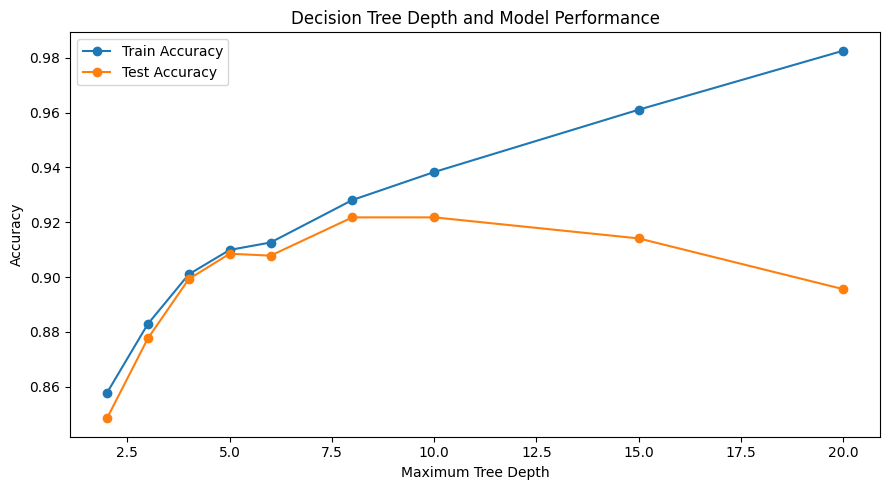

In [ ]:
plot_depth = depth_df[
    depth_df['Max Depth'] != 'None'
].copy()

plt.figure(figsize=(9, 5))

plt.plot(
    plot_depth['Depth Value'],
    plot_depth['Train Accuracy'],
    marker='o',
    label='Train Accuracy'
)

plt.plot(
    plot_depth['Depth Value'],
    plot_depth['Test Accuracy'],
    marker='o',
    label='Test Accuracy'
)

plt.xlabel('Maximum Tree Depth')
plt.ylabel('Accuracy')

plt.title(
    'Decision Tree Depth and Model Performance'
)

plt.legend()

plt.tight_layout()
plt.show()

In [ ]:
best_depth_row = depth_df.loc[
    depth_df['F1 Score'].idxmax()
]

best_depth = best_depth_row[
    'Max Depth'
]

print(
    "Best maximum depth based on F1:",
    best_depth
)

display(
    best_depth_row.to_frame().T
)

Best maximum depth based on F1: 10


,Max Depth,Depth Value,Train Accuracy,Test Accuracy,Precision,Recall,F1 Score
6,10,10,0.938324,0.921788,0.922258,0.697824,0.794495


## Tuned Decision Tree

After comparing the different tree depths, I selected the depth with the highest F1 score.

I used F1 instead of accuracy alone because the dataset contains fewer defaults than non-defaults. F1 considers both precision and recall, which gives me a better idea of how well the model is identifying the default class.

In [ ]:
best_depth_value = (
    None
    if best_depth == 'None'
    else int(best_depth)
)

tuned_tree = Pipeline(
    steps=[
        (
            'preprocessor',
            preprocessor
        ),
        (
            'tree',
            DecisionTreeClassifier(
                max_depth=best_depth_value,
                random_state=42
            )
        )
    ]
)

tuned_tree.fit(
    X_train,
    y_train
)

tuned_tree_pred = tuned_tree.predict(
    X_test
)

tuned_tree_prob = tuned_tree.predict_proba(
    X_test
)[:, 1]

tuned_tree_accuracy = accuracy_score(
    y_test,
    tuned_tree_pred
)

tuned_tree_precision = precision_score(
    y_test,
    tuned_tree_pred
)

tuned_tree_recall = recall_score(
    y_test,
    tuned_tree_pred
)

tuned_tree_f1 = f1_score(
    y_test,
    tuned_tree_pred
)

tuned_tree_auc = roc_auc_score(
    y_test,
    tuned_tree_prob
)

print("Tuned Decision Tree")
print("-" * 40)

print(
    f"Maximum Depth: {best_depth}"
)

print(
    f"Accuracy:      {tuned_tree_accuracy:.4f}"
)

print(
    f"Precision:     {tuned_tree_precision:.4f}"
)

print(
    f"Recall:        {tuned_tree_recall:.4f}"
)

print(
    f"F1 Score:      {tuned_tree_f1:.4f}"
)

print(
    f"ROC-AUC:       {tuned_tree_auc:.4f}"
)

Tuned Decision Tree
----------------------------------------
Maximum Depth: 10
Accuracy:      0.9218
Precision:     0.9223
Recall:        0.6978
F1 Score:      0.7945
ROC-AUC:       0.8964


## Decision Tree Structure

One advantage of a decision tree is that I can visualize how it makes decisions.

The full tree can become difficult to read, so I displayed only the first few levels. This gives me an idea of which variables are being used near the top of the tree and are therefore making some of the earliest splits in the data.

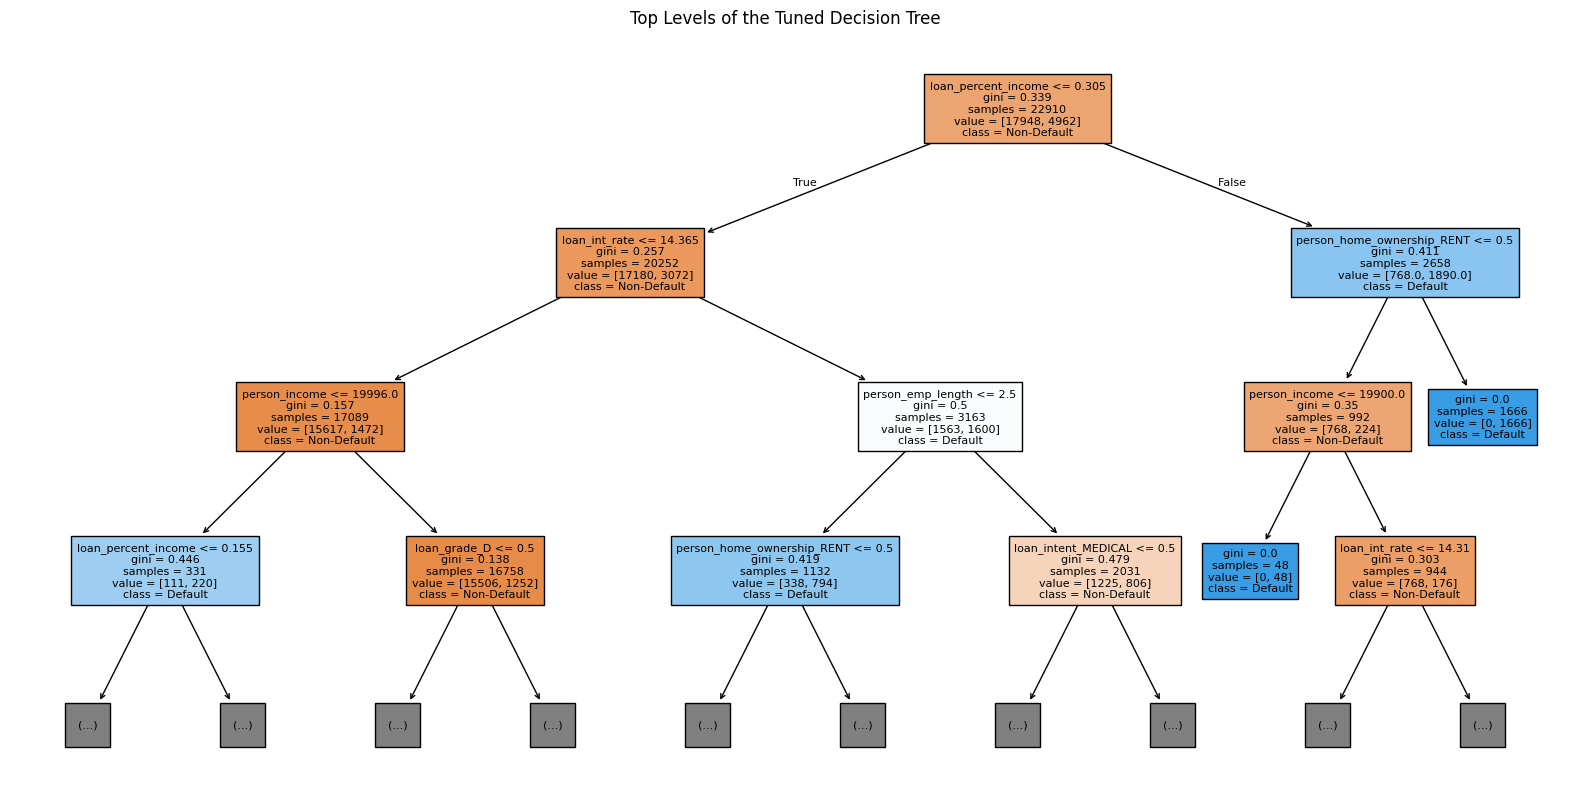

In [ ]:
feature_names = (
    tuned_tree
    .named_steps['preprocessor']
    .get_feature_names_out()
)

feature_names = [
    name.replace('continuous__', '')
        .replace('categorical__', '')
    for name in feature_names
]

plt.figure(figsize=(20, 10))

plot_tree(
    tuned_tree.named_steps['tree'],
    feature_names=feature_names,
    class_names=[
        'Non-Default',
        'Default'
    ],
    filled=True,
    max_depth=3,
    fontsize=8
)

plt.title(
    'Top Levels of the Tuned Decision Tree'
)

plt.show()

## Random Forest

Next, I used a random forest. Instead of relying on a single decision tree, a random forest creates many trees and combines their predictions.

Individual decision trees can be unstable and may overfit the training data. A random forest can reduce some of this problem by averaging predictions across many different trees.

I started with 100 trees and compared the results with the single decision tree.

In [ ]:
forest_model = Pipeline(
    steps=[
        (
            'preprocessor',
            preprocessor
        ),
        (
            'forest',
            RandomForestClassifier(
                n_estimators=100,
                random_state=42,
                n_jobs=-1
            )
        )
    ]
)

forest_model.fit(
    X_train,
    y_train
)

forest_train_pred = forest_model.predict(
    X_train
)

forest_test_pred = forest_model.predict(
    X_test
)

forest_test_prob = forest_model.predict_proba(
    X_test
)[:, 1]

In [ ]:
forest_train_accuracy = accuracy_score(
    y_train,
    forest_train_pred
)

forest_accuracy = accuracy_score(
    y_test,
    forest_test_pred
)

forest_precision = precision_score(
    y_test,
    forest_test_pred
)

forest_recall = recall_score(
    y_test,
    forest_test_pred
)

forest_f1 = f1_score(
    y_test,
    forest_test_pred
)

forest_auc = roc_auc_score(
    y_test,
    forest_test_prob
)

print("Random Forest")
print("-" * 40)

print(
    f"Training Accuracy: {forest_train_accuracy:.4f}"
)

print(
    f"Testing Accuracy:  {forest_accuracy:.4f}"
)

print(
    f"Precision:         {forest_precision:.4f}"
)

print(
    f"Recall:            {forest_recall:.4f}"
)

print(
    f"F1 Score:          {forest_f1:.4f}"
)

print(
    f"ROC-AUC:           {forest_auc:.4f}"
)

Random Forest
----------------------------------------
Training Accuracy: 1.0000
Testing Accuracy:  0.9281
Precision:         0.9530
Recall:            0.7027
F1 Score:          0.8089
ROC-AUC:           0.9254


## Number of Trees

I also tested different numbers of trees to see whether adding more estimators improved the random forest.

Increasing the number of trees can make the model more stable, but after a certain point the improvement may become very small while computation time continues to increase.

I compared 50, 100, 200, and 300 trees.

In [ ]:
estimator_values = [
    50,
    100,
    200,
    300
]

forest_results = []

for n in estimator_values:

    model = Pipeline(
        steps=[
            (
                'preprocessor',
                preprocessor
            ),
            (
                'forest',
                RandomForestClassifier(
                    n_estimators=n,
                    random_state=42,
                    n_jobs=-1
                )
            )
        ]
    )

    model.fit(
        X_train,
        y_train
    )

    train_pred = model.predict(
        X_train
    )

    test_pred = model.predict(
        X_test
    )

    test_prob = model.predict_proba(
        X_test
    )[:, 1]

    forest_results.append({
        'Trees': n,

        'Train Accuracy':
            accuracy_score(
                y_train,
                train_pred
            ),

        'Test Accuracy':
            accuracy_score(
                y_test,
                test_pred
            ),

        'Precision':
            precision_score(
                y_test,
                test_pred
            ),

        'Recall':
            recall_score(
                y_test,
                test_pred
            ),

        'F1 Score':
            f1_score(
                y_test,
                test_pred
            ),

        'ROC-AUC':
            roc_auc_score(
                y_test,
                test_prob
            )
    })

forest_df = pd.DataFrame(
    forest_results
)

forest_df.round(4)

,Trees,Train Accuracy,Test Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,50,0.9994,0.9269,0.9487,0.7002,0.8057,0.9236
1,100,1.0000,0.9281,0.9530,0.7027,0.8089,0.9254
2,200,1.0000,0.9274,0.9518,0.7002,0.8069,0.9274
3,300,1.0000,0.9284,0.9571,0.7010,0.8093,0.9282


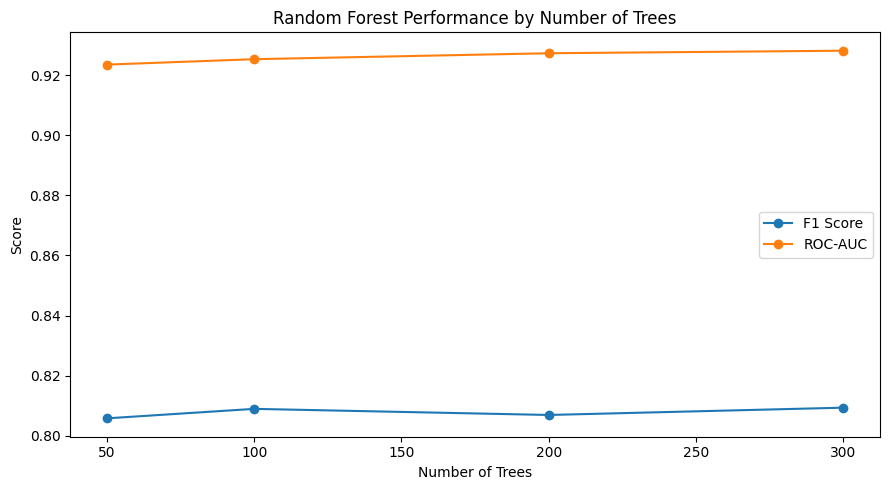

In [ ]:
plt.figure(figsize=(9, 5))

plt.plot(
    forest_df['Trees'],
    forest_df['F1 Score'],
    marker='o',
    label='F1 Score'
)

plt.plot(
    forest_df['Trees'],
    forest_df['ROC-AUC'],
    marker='o',
    label='ROC-AUC'
)

plt.xlabel(
    'Number of Trees'
)

plt.ylabel(
    'Score'
)

plt.title(
    'Random Forest Performance by Number of Trees'
)

plt.legend()

plt.tight_layout()
plt.show()

In [ ]:
best_forest_row = forest_df.loc[
    forest_df['F1 Score'].idxmax()
]

best_n_estimators = int(
    best_forest_row['Trees']
)

print(
    "Best number of trees based on F1:",
    best_n_estimators
)

display(
    best_forest_row.to_frame().T
)

Best number of trees based on F1: 300


,Trees,Train Accuracy,Test Accuracy,Precision,Recall,F1 Score,ROC-AUC
3,300.0,1.0,0.928422,0.957096,0.701048,0.809302,0.928198


In [ ]:
tuned_forest = Pipeline(
    steps=[
        (
            'preprocessor',
            preprocessor
        ),
        (
            'forest',
            RandomForestClassifier(
                n_estimators=best_n_estimators,
                random_state=42,
                n_jobs=-1
            )
        )
    ]
)

tuned_forest.fit(
    X_train,
    y_train
)

tuned_forest_pred = tuned_forest.predict(
    X_test
)

tuned_forest_prob = tuned_forest.predict_proba(
    X_test
)[:, 1]

tuned_forest_accuracy = accuracy_score(
    y_test,
    tuned_forest_pred
)

tuned_forest_precision = precision_score(
    y_test,
    tuned_forest_pred
)

tuned_forest_recall = recall_score(
    y_test,
    tuned_forest_pred
)

tuned_forest_f1 = f1_score(
    y_test,
    tuned_forest_pred
)

tuned_forest_auc = roc_auc_score(
    y_test,
    tuned_forest_prob
)

print("Tuned Random Forest")
print("-" * 40)

print(
    f"Trees:      {best_n_estimators}"
)

print(
    f"Accuracy:   {tuned_forest_accuracy:.4f}"
)

print(
    f"Precision:  {tuned_forest_precision:.4f}"
)

print(
    f"Recall:     {tuned_forest_recall:.4f}"
)

print(
    f"F1 Score:   {tuned_forest_f1:.4f}"
)

print(
    f"ROC-AUC:    {tuned_forest_auc:.4f}"
)

Tuned Random Forest
----------------------------------------
Trees:      300
Accuracy:   0.9284
Precision:  0.9571
Recall:     0.7010
F1 Score:   0.8093
ROC-AUC:    0.9282


## Random Forest Feature Importance

Another advantage of random forests is that I can look at feature importance.

Feature importance shows which variables contributed the most to the decisions made across the trees. This can help connect the predictive model back to the credit risk question by showing which borrower and loan characteristics are most useful for predicting default.

In [ ]:
feature_names = (
    tuned_forest
    .named_steps['preprocessor']
    .get_feature_names_out()
)

feature_names = [
    name.replace('continuous__', '')
        .replace('categorical__', '')
    for name in feature_names
]

importance = (
    tuned_forest
    .named_steps['forest']
    .feature_importances_
)

importance_df = pd.DataFrame({
    'Feature': feature_names,
    'Importance': importance
})

importance_df = importance_df.sort_values(
    'Importance',
    ascending=False
)

display(
    importance_df.round(4)
)

,Feature,Importance
5,loan_percent_income,0.2148
1,person_income,0.1461
4,loan_int_rate,0.1340
3,loan_amnt,0.0794
9,person_home_ownership_RENT,0.0762
2,person_emp_length,0.0611
17,loan_grade_D,0.0541
0,person_age,0.0478
6,cb_person_cred_hist_length,0.0375
8,person_home_ownership_OWN,0.0173


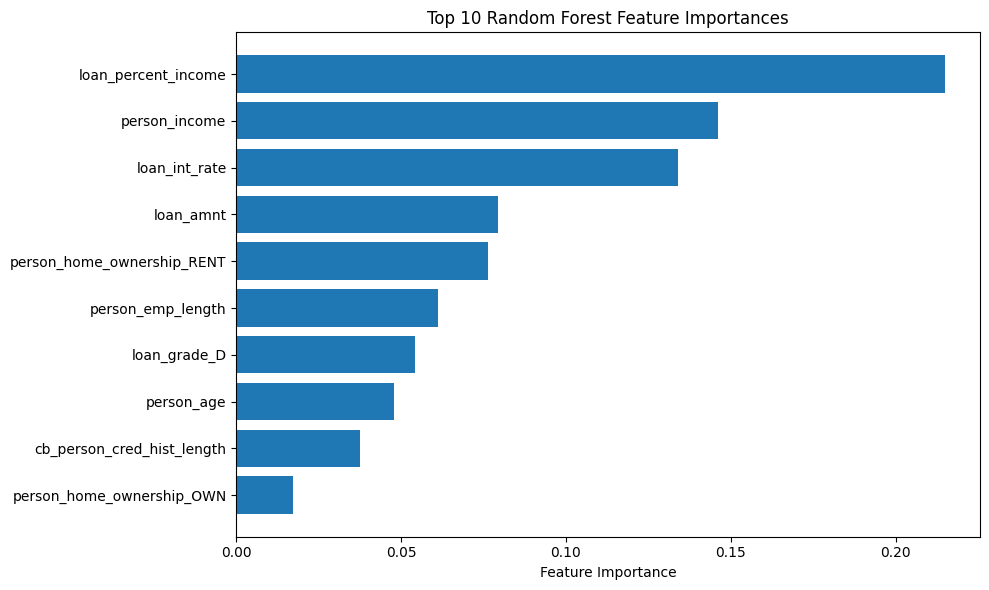

In [ ]:
top_importance = (
    importance_df
    .head(10)
    .sort_values('Importance')
)

plt.figure(figsize=(10, 6))

plt.barh(
    top_importance['Feature'],
    top_importance['Importance']
)

plt.xlabel(
    'Feature Importance'
)

plt.title(
    'Top 10 Random Forest Feature Importances'
)

plt.tight_layout()
plt.show()

## Confusion Matrix

I used the confusion matrix to look more closely at the random forest predictions.

As in Weeks 4 and 5, I am especially interested in false negatives because these are borrowers who actually defaulted but were predicted as non-defaults.

This will also make it easier to compare the random forest with the SVM from Week 5.

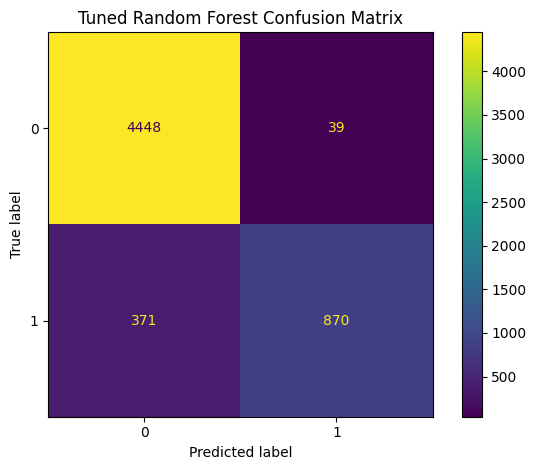

In [ ]:
ConfusionMatrixDisplay.from_predictions(
    y_test,
    tuned_forest_pred
)

plt.title(
    'Tuned Random Forest Confusion Matrix'
)

plt.tight_layout()
plt.show()

<Figure size 800x600 with 0 Axes>

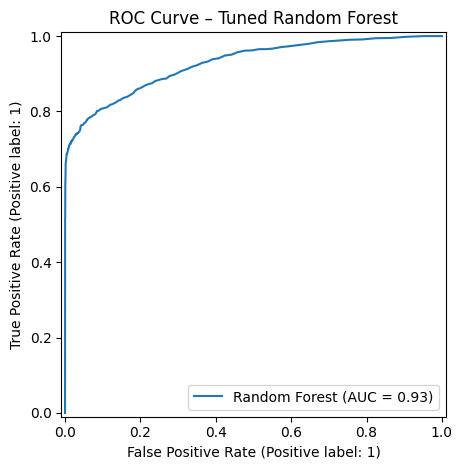

In [ ]:
plt.figure(figsize=(8, 6))

RocCurveDisplay.from_predictions(
    y_test,
    tuned_forest_prob,
    name='Random Forest'
)

plt.title(
    'ROC Curve – Tuned Random Forest'
)

plt.tight_layout()
plt.show()

## Model Comparison

I compared the tuned decision tree and random forest with the tuned RBF SVM from Week 5.

Since all three models use the same target and predictors, this gives me a direct comparison of how the different classification methods perform on the credit risk data.

I am especially interested in recall and F1 score because identifying actual defaults is more important for this analysis than looking at accuracy alone.

In [ ]:
model_comparison = pd.DataFrame({
    'Model': [
        'Week 5 Tuned RBF SVM',
        'Week 6 Tuned Decision Tree',
        'Week 6 Random Forest'
    ],

    'Accuracy': [
        0.9148,
        tuned_tree_accuracy,
        tuned_forest_accuracy
    ],

    'Precision': [
        0.9333,
        tuned_tree_precision,
        tuned_forest_precision
    ],

    'Recall': [
        0.6535,
        tuned_tree_recall,
        tuned_forest_recall
    ],

    'F1 Score': [
        0.7687,
        tuned_tree_f1,
        tuned_forest_f1
    ],

    'ROC-AUC': [
        0.8994,
        tuned_tree_auc,
        tuned_forest_auc
    ]
})

model_comparison.round(4)

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Week 5 Tuned RBF SVM,0.9148,0.9333,0.6535,0.7687,0.8994
1,Week 6 Tuned Decision Tree,0.9218,0.9223,0.6978,0.7945,0.8964
2,Week 6 Random Forest,0.9284,0.9571,0.7010,0.8093,0.9282


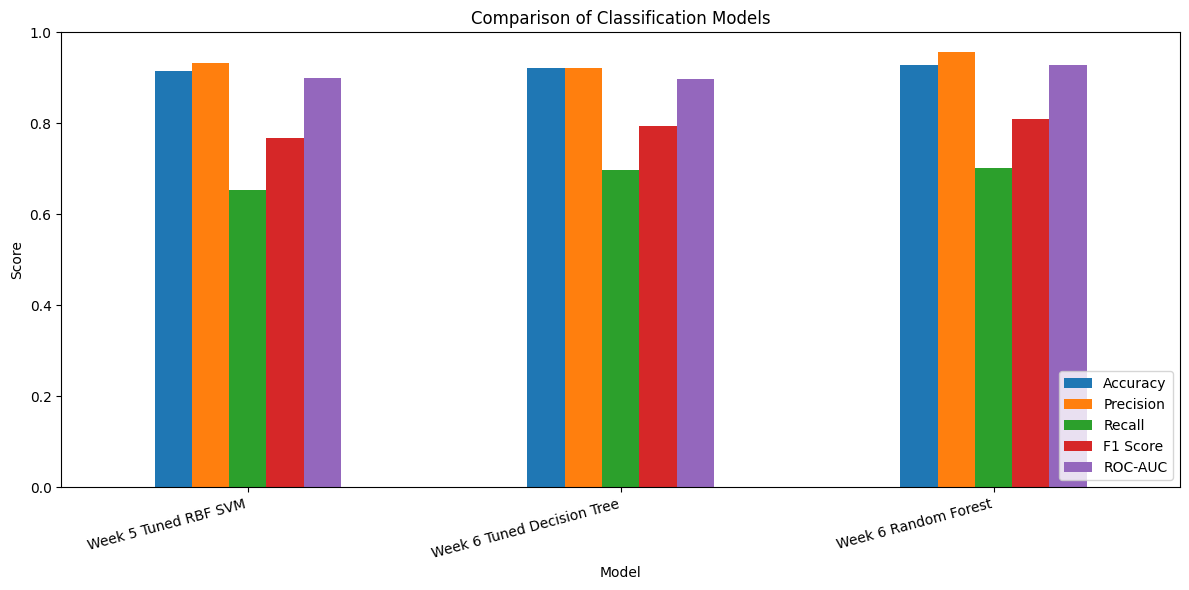

In [ ]:
plot_comparison = (
    model_comparison
    .set_index('Model')
)

plot_comparison.plot(
    kind='bar',
    figsize=(12, 6)
)

plt.ylabel('Score')

plt.title(
    'Comparison of Classification Models'
)

plt.ylim(0, 1)

plt.xticks(
    rotation=15,
    ha='right'
)

plt.legend(
    loc='lower right'
)

plt.tight_layout()
plt.show()

In [ ]:
forest_cm = confusion_matrix(
    y_test,
    tuned_forest_pred
)

tn, fp, fn, tp = forest_cm.ravel()

best_model = model_comparison.loc[
    model_comparison['F1 Score'].idxmax(),
    'Model'
]

print("WEEK 6 MODEL SUMMARY")
print("=" * 60)

print(
    "Untuned Tree Training Accuracy:",
    round(tree_train_accuracy, 4)
)

print(
    "Untuned Tree Testing Accuracy:",
    round(tree_accuracy, 4)
)

print(
    "Best Decision Tree Depth:",
    best_depth
)

print(
    "Best Number of Random Forest Trees:",
    best_n_estimators
)

print(
    "Best Model by F1 Score:",
    best_model
)

print("\nTuned Random Forest")
print("-" * 60)

print(
    f"Accuracy: {tuned_forest_accuracy:.4f}"
)

print(
    f"Precision: {tuned_forest_precision:.4f}"
)

print(
    f"Recall: {tuned_forest_recall:.4f}"
)

print(
    f"F1 Score: {tuned_forest_f1:.4f}"
)

print(
    f"ROC-AUC: {tuned_forest_auc:.4f}"
)

print("\nConfusion Matrix")
print("-" * 60)

print("True Negatives:", tn)
print("False Positives:", fp)
print("False Negatives:", fn)
print("True Positives:", tp)

print("\nTop 10 Features")
print("-" * 60)

display(
    importance_df
    .head(10)
    .round(4)
)

WEEK 6 MODEL SUMMARY
Untuned Tree Training Accuracy: 1.0
Untuned Tree Testing Accuracy: 0.8808
Best Decision Tree Depth: 10
Best Number of Random Forest Trees: 300
Best Model by F1 Score: Week 6 Random Forest

Tuned Random Forest
------------------------------------------------------------
Accuracy: 0.9284
Precision: 0.9571
Recall: 0.7010
F1 Score: 0.8093
ROC-AUC: 0.9282

Confusion Matrix
------------------------------------------------------------
True Negatives: 4448
False Positives: 39
False Negatives: 371
True Positives: 870

Top 10 Features
------------------------------------------------------------


,Feature,Importance
5,loan_percent_income,0.2148
1,person_income,0.1461
4,loan_int_rate,0.1340
3,loan_amnt,0.0794
9,person_home_ownership_RENT,0.0762
2,person_emp_length,0.0611
17,loan_grade_D,0.0541
0,person_age,0.0478
6,cb_person_cred_hist_length,0.0375
8,person_home_ownership_OWN,0.0173


## Week 6 Conclusions

For Week 6, I used decision trees and random forests to predict loan default. I first looked at a decision tree without limiting its depth, then tested different maximum depths to see how controlling the complexity of the tree affected performance. I also compared the decision tree with a random forest and looked at which features were most important to the random forest predictions.

### Decision Tree and Overfitting

The original decision tree had a training accuracy of 1.0000 but a testing accuracy of only 0.8808. The tree reached a depth of 32 and had 2,016 leaves.

The perfect training accuracy combined with the lower testing accuracy showed that the unrestricted tree was overfitting the training data. It was able to classify all of the training observations correctly, but this did not translate to the same level of performance on new data.

Testing different maximum depths helped control this problem. A maximum depth of 10 produced the highest F1 score of 0.7945. The tuned tree had an accuracy of 0.9218, precision of 0.9223, recall of 0.6978, and ROC-AUC of 0.8964.

This was a noticeable improvement over the unrestricted tree and showed that allowing a decision tree to become more complex does not necessarily make it better at predicting new observations.

### Random Forest

The random forest performed better than the single decision tree. I tested 50, 100, 200, and 300 trees, and the differences between them were fairly small. The model with 300 trees had the highest F1 score at 0.8093 and the highest ROC-AUC at 0.9282.

The final random forest had an accuracy of 0.9284, precision of 0.9571, recall of 0.7010, and F1 score of 0.8093.

The confusion matrix showed that the model correctly identified 4,448 non-defaults and 870 defaults. It produced only 39 false positives but missed 371 borrowers who actually defaulted.

The random forest still had a training accuracy of 1.0000, so there is some evidence that the individual trees are fitting the training data very closely. However, its testing performance was much stronger than the unrestricted single decision tree. This shows the benefit of combining many trees instead of relying on one tree.

### Feature Importance

The most important feature in the random forest was `loan_percent_income`, with an importance of 0.2148. This was followed by `person_income` at 0.1461 and `loan_int_rate` at 0.1340.

Loan amount, renting a home, employment length, and loan grade D were also among the more important predictors.

I found the importance of `loan_percent_income` especially interesting because this variable also appeared to be important in the Week 4 logistic regression analysis. This suggests that the size of a loan relative to a borrower's income may be an important factor for predicting default across different types of models.

### Comparison with Week 5

Both of the tuned Week 6 models performed well compared with the tuned RBF SVM from Week 5. The tuned decision tree increased recall from 0.6535 with the SVM to 0.6978, although its ROC-AUC was slightly lower.

The random forest performed better than the SVM across all of the metrics I compared. Accuracy increased from 0.9148 to 0.9284, precision increased from 0.9333 to 0.9571, recall increased from 0.6535 to 0.7010, and F1 increased from 0.7687 to 0.8093. ROC-AUC also increased from 0.8994 to 0.9282.

### Overall Conclusion

Overall, the random forest was the strongest classification model I have tested so far for predicting loan default. It performed better than both the single decision tree and the tuned RBF SVM from Week 5.

One of the most useful findings from this week was seeing how clearly the unrestricted decision tree overfit the training data. Limiting the depth improved its ability to generalize, while the random forest improved performance even further by combining predictions from many trees.

Across Weeks 4 through 6, model performance has continued to improve as I moved from logistic regression to SVM and then to random forest. The random forest currently provides the best balance of precision, recall, F1 score, and ROC-AUC for identifying borrowers who are at risk of default.